In [ ]:
import numpy as np
import pandas as pd
import keras
import tensorflow as tf
import cv2
import os
import kagglehub
import random
from scipy import ndimage
from skimage import morphology
from tqdm import tqdm
from keras import layers
from PIL import Image
from IPython.display import display
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

random.seed(1)
np.random.seed = 1

In [ ]:
IMG_WIDTH = 576
IMG_HEIGHT = 384
IMG_CHANNELS = 3

APO_TRAIN_PATH = '/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/apo_imgs_v1/apo_images_new_model_v1/'
APO_MASK_PATH = '/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/apo_masks_v1/apo_masks_new_model_v1/'
ApoTrainFiles = sorted([f for f in os.listdir(APO_TRAIN_PATH) if f.endswith('.tif') and os.path.isfile(os.path.join(APO_TRAIN_PATH, f))])
ApoMaskFiles = sorted([f for f in os.listdir(APO_MASK_PATH) if f.endswith('.tif') and os.path.isfile(os.path.join(APO_MASK_PATH, f))])
FASC_TRAIN_PATH = "/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/fasc_imgs_v1/fasc_images_new_model_v1/"
FASC_MASK_PATH = "/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/fasc_masks_v1/fasc_masks_new_model_v1/"
FascTrainFiles = sorted([f for f in os.listdir(FASC_TRAIN_PATH) if f.endswith('.tif') and os.path.isfile(os.path.join(APO_TRAIN_PATH, f))])
FascMaskFiles = sorted([f for f in os.listdir(FASC_MASK_PATH) if f.endswith('.tif') and os.path.isfile(os.path.join(APO_TRAIN_PATH, f))])
#limiting the sample size here for faster testing
# ApoTrainFiles = ApoTrainFiles[:35]
# ApoMaskFiles = ApoMaskFiles[:35]
# ApoTestFiles = ApoTestFiles[:10]

Apo_X_Train = np.zeros((len(ApoTrainFiles), IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), dtype=np.float32)
Apo_Y_Train = np.zeros((len(ApoTrainFiles), IMG_HEIGHT, IMG_WIDTH, 1), dtype=np.float32)
Fasc_X_Train = np.zeros((len(FascTrainFiles), IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), dtype=np.float32)
Fasc_Y_Train = np.zeros((len(FascTrainFiles), IMG_HEIGHT, IMG_WIDTH, 1), dtype=np.float32)

for n, file in tqdm(enumerate(ApoTrainFiles), total=(len(ApoTrainFiles))):
    img = cv2.imread(APO_TRAIN_PATH + file)[:,:,:IMG_CHANNELS]
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
    Apo_X_Train[n] = img
    img = cv2.imread(FASC_TRAIN_PATH + file)[:,:,:IMG_CHANNELS]
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
    Fasc_X_Train[n] = img
    if os.path.exists(APO_MASK_PATH + file):
        mask = cv2.imread(APO_MASK_PATH + file, cv2.IMREAD_GRAYSCALE)    
        mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
        mask_binary = (mask > 127).astype(np.float32)
        Apo_Y_Train[n] = np.expand_dims(mask_binary, axis=-1)
    if os.path.exists(FASC_MASK_PATH + file):
        mask = cv2.imread(FASC_MASK_PATH + file, cv2.IMREAD_GRAYSCALE)    
        mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
        mask_binary = (mask > 127).astype(np.float32)
        Fasc_Y_Train[n] = np.expand_dims(mask_binary, axis=-1)
        
    

In [ ]:
# matrix sanity check. displays reesized image
img = np.squeeze(Apo_Y_Train[4]) #becomes single image shape
if img.dtype != np.uint8:
    if img.max() <= 1:
        img = (img * 255).astype(np.uint8)
    else:
        img = img.astype(np.uint8)
pilImg = Image.fromarray(img, mode='L')
display(pilImg)

In [ ]:
img = Image.open("/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/test_images_v2/test_set_v2/IMG_00001.tif")
display(img)
print(f"Size/Dimensions: {img.size}")
print(f"Width: {img.width}")
print(f"Height: {img.height}")
print(f"Color Mode: {img.mode}")

In [ ]:
def buildModel():
    # Dimensions adjusted to be cleanly divisible by 128 (2^7) to avoid pooling rounding mismatches
    IMG_WIDTH = 576
    IMG_HEIGHT = 384
    IMG_CHANNELS = 3
    
    inputs = tf.keras.layers.Input((IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))

    s = tf.keras.layers.Lambda(lambda x: x / 255)(inputs)
    conv1 = tf.keras.layers.Conv2D(16, (3, 3), activation="relu", kernel_initializer="he_normal", padding="same")(s)
    conv1 = tf.keras.layers.GroupNormalization(groups=2)(conv1)
    conv1 = tf.keras.layers.Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv1)
    pool1 = tf.keras.layers.MaxPooling2D((2, 2))(conv1)

    conv2 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(pool1)
    conv2 = tf.keras.layers.GroupNormalization(groups=2)(conv2)
    conv2 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv2)
    pool2 = tf.keras.layers.MaxPooling2D((2, 2))(conv2)

    conv3 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(pool2)
    conv3 = tf.keras.layers.GroupNormalization(groups=2)(conv3)
    conv3 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv3)
    pool3 = tf.keras.layers.MaxPooling2D((2, 2))(conv3)

    conv4 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(pool3)
    conv4 = tf.keras.layers.GroupNormalization(groups=2)(conv4)
    conv4 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv4)
    pool4 = tf.keras.layers.MaxPooling2D(pool_size=(2, 2))(conv4)

    conv5 = tf.keras.layers.Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(pool4)
    conv5 = tf.keras.layers.GroupNormalization(groups=2)(conv5)
    conv5 = tf.keras.layers.Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv5)

    #start upsample
    
    upsample6 = tf.keras.layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv5)
    upsample6 = tf.keras.layers.concatenate([upsample6, conv4])
    conv6 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(upsample6)
    conv6 = tf.keras.layers.GroupNormalization(groups=2)(conv6)
    conv6 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv6)

    upsample7 = tf.keras.layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv6)
    upsample7 = tf.keras.layers.concatenate([upsample7, conv3])
    conv7 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(upsample7)
    conv7 = tf.keras.layers.GroupNormalization(groups=2)(conv7)
    conv7 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv7)

    upsample8 = tf.keras.layers.Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(conv7)
    upsample8 = tf.keras.layers.concatenate([upsample8, conv2])
    conv8 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(upsample8)
    conv8 = tf.keras.layers.GroupNormalization(groups=2)(conv8)
    conv8 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv8)

    upsample9 = tf.keras.layers.Conv2DTranspose(16, (2, 2), strides=(2, 2), padding='same')(conv8)
    upsample9 = tf.keras.layers.concatenate([upsample9, conv1])
    conv9 = tf.keras.layers.Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(upsample9)
    conv9 = tf.keras.layers.GroupNormalization(groups=2)(conv9)
    conv9 = tf.keras.layers.Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(conv9)

    outputs = tf.keras.layers.Conv2D(1, (1, 1), activation='sigmoid')(conv9)
    model = tf.keras.Model(inputs=[inputs], outputs=[outputs])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return model

In [ ]:
strategy = tf.distribute.MirroredStrategy()
with strategy.scope():
    apoModel = buildModel()
apoModel.summary()

In [ ]:
checkpoint = tf.keras.callbacks.ModelCheckpoint("/kaggle/working/apo-u-net.h5", verbose=1, save_best_only=True)
callbacks = [tf.keras.callbacks.EarlyStopping(patience=3, monitor='val_loss'),
            tf.keras.callbacks.TensorBoard(log_dir='logs')]
results = apoModel.fit(Apo_X_Train, Apo_Y_Train, validation_split=0.25, batch_size=16, epochs=100, callbacks=callbacks)

In [ ]:
strategy = tf.distribute.MirroredStrategy()
with strategy.scope():
    fascModel = buildModel()
fascCheckpoint = tf.keras.callbacks.ModelCheckpoint("/kaggle/working/fasc-u-net.h5", verbose=1, save_best_only=True)
callbacks = [tf.keras.callbacks.EarlyStopping(patience=3, monitor='val_loss'),
            tf.keras.callbacks.TensorBoard(log_dir='logs')]
fascResults = fascModel.fit(Fasc_X_Train, Fasc_Y_Train, validation_split=0.25, batch_size=16, epochs=100, callbacks=callbacks)

In [ ]:
sharedInf = tf.keras.Input(shape=(384, 576, 3))
mask1 = fascModel(sharedInf)
mask2 = apoModel(sharedInf)
combinedOutputs = tf.keras.layers.Concatenate(axis=-1)([mask1[0], mask2[0]])
combinedModel = tf.keras.Model(inputs=sharedInf, outputs=combinedOutputs)
combinedModel.summary()

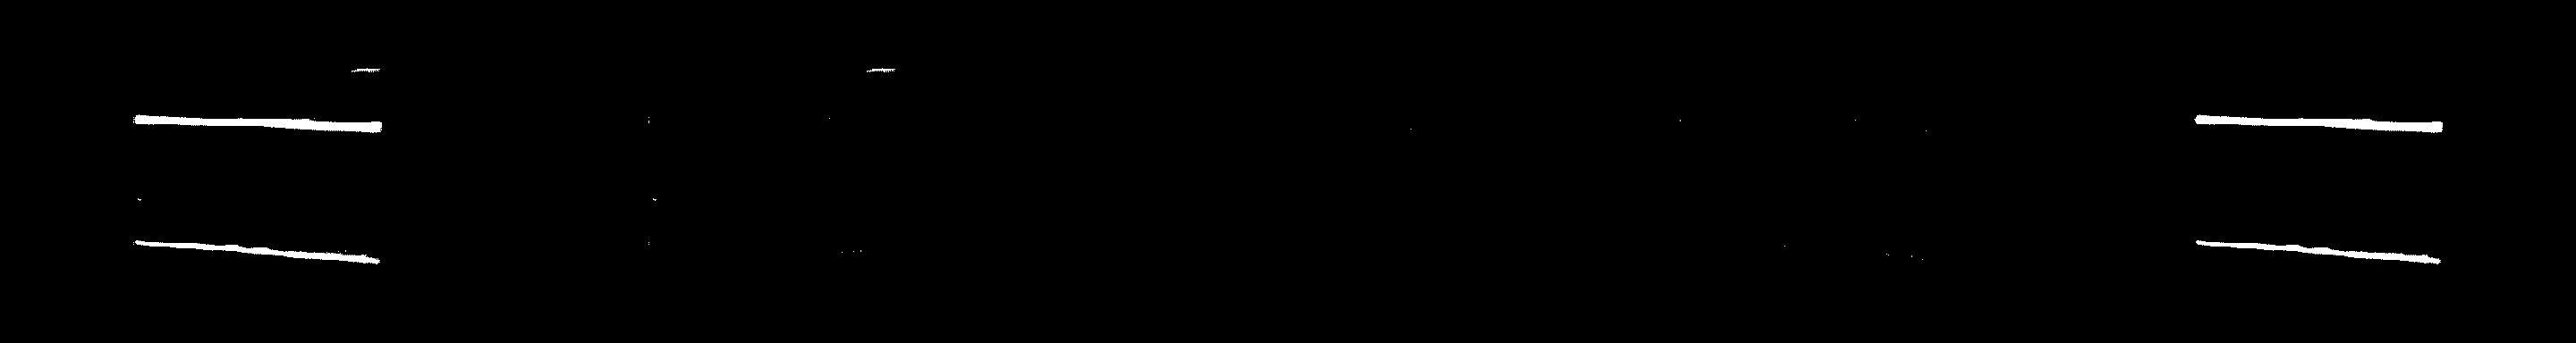

In [92]:
#Image post-processing
img = testPredict[0]
fascMask = (img[:, :, 0] > 0.5).astype(np.uint8) * 255
apoMask = (img[:, :, 1] > 0.5).astype(np.uint8) * 255
def apoCleanUp(mask, threshold=0.5, minSize=80, holeSize=15):
    binMask = mask > threshold
    cleanArtifacts = morphology.remove_small_objects(binMask, minSize)
    deletedNoise = (binMask & ~cleanArtifacts)
    filledMask = morphology.remove_small_holes(cleanArtifacts, area_threshold=holeSize)
    filledHoles = (filledMask & ~cleanArtifacts)
    footprint = morphology.disk(radius=3)
    closedMask = ndimage.binary_closing(filledMask, structure=footprint)
    closedEdges = (closedMask & ~filledMask)
    stitchImages([mask, deletedNoise, filledHoles, closedEdges, closedMask])
    return closedMask
    
apoMask = apoCleanUp(apoMask)
#fasc lines are too thin to attempt a clean up

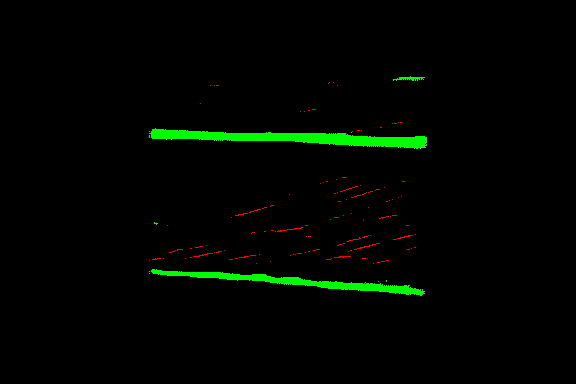

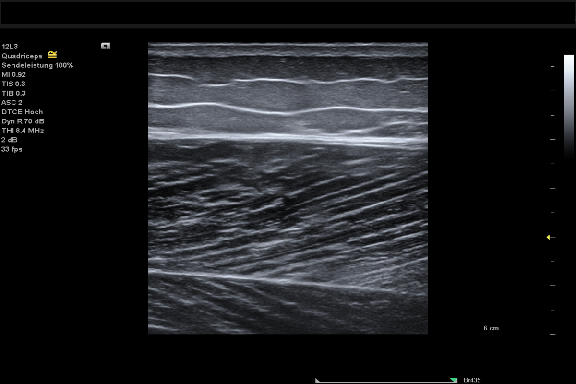

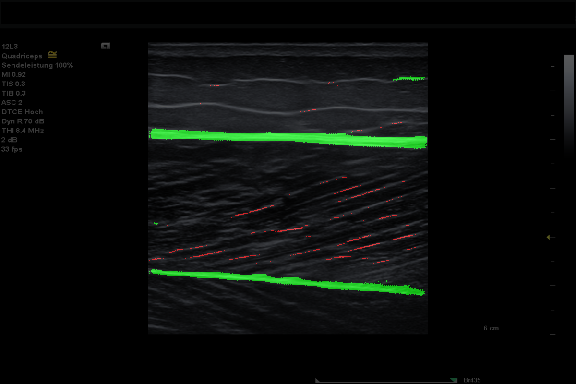

In [42]:
img = testPredict[0]
mask1 = (img[:, :, 0] > 0.5).astype(np.uint8) * 255
mask2 = (img[:, :, 1] > 0.5).astype(np.uint8) * 255
blank_channel = np.zeros_like(mask1)
rgb_array = np.stack([mask1, mask2, blank_channel], axis=-1)
combined_image = Image.fromarray(rgb_array, mode='RGB')
display(combined_image)
img = Image.open("/kaggle/input/competitions/umud-challenge-muscle-architecture-in-ultrasound-data/test_images_v2/test_set_v2/IMG_00005.tif")
img = img.resize((IMG_WIDTH, IMG_HEIGHT), resample=Image.NEAREST)
display(img)
overlay_result = Image.blend(combined_image, img, alpha=0.35)
display(overlay_result)

